In [1]:
#importing libraries

import seaborn as sns
sns.set(style='darkgrid')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

import warnings
warnings.filterwarnings('ignore')


In [3]:
df=pd.read_csv("/content/ABC Company.xlsx - Sheet1.csv")
df.head(5)


,Name,Team,Number,Position,Age,Height,Weight,College,Salary
0,Avery Bradley,Boston Celtics,0,PG,25,06-Feb,180,Texas,7730337.0
1,Jae Crowder,Boston Celtics,99,SF,25,06-Jun,235,Marquette,6796117.0
2,John Holland,Boston Celtics,30,SG,27,06-May,205,Boston University,NaN
3,R.J. Hunter,Boston Celtics,28,SG,22,06-May,185,Georgia State,1148640.0
4,Jonas Jerebko,Boston Celtics,8,PF,29,06-Oct,231,NaN,5000000.0


In [4]:
df.shape

(458, 9)

**Preprocessing**

In [5]:

df['Height'] = np.random.randint(150, 181, size=len(df))

In [6]:
print(df['Height'].head())
print(df['Height'].min())
print(df['Height'].max())
print(df['Height'].isnull().sum())

0    166
1    172
2    174
3    170
4    177
Name: Height, dtype: int64
150
180
0


**Analysis tasks**

In [7]:
#1.
# Calculate employee count per team
team_counts = df['Team'].value_counts()

# Calculate percentage split relative to total employees
team_percentages = (df['Team'].value_counts(normalize=True) * 100).round(2)

# Combine into a single summary DataFrame
team_distribution = pd.DataFrame({
    'Employee Count': team_counts,
    'Percentage (%)': team_percentages
})

# Display the team distribution summary
display(team_distribution)

,Employee Count,Percentage (%)
Team,,
New Orleans Pelicans,19,4.15
Memphis Grizzlies,18,3.93
Utah Jazz,16,3.49
Milwaukee Bucks,16,3.49
New York Knicks,16,3.49
Boston Celtics,15,3.28
Los Angeles Clippers,15,3.28
Los Angeles Lakers,15,3.28
Phoenix Suns,15,3.28


In [8]:
#2.
#Count employees by position
position_counts = df['Position'].value_counts()
print(position_counts)

Position
SG    102
PF    100
PG     92
SF     85
C      79
Name: count, dtype: int64


In [9]:
position_distribution = position_counts.reset_index()
position_distribution.columns = ['Position', 'Employee Count']
display(position_distribution)

,Position,Employee Count
0,SG,102
1,PF,100
2,PG,92
3,SF,85
4,C,79


In [10]:
# 3. Identify the predominant age group among employees
min_age = df['Age'].min()
max_age = df['Age'].max()
print(f"Age range: {min_age} to {max_age} years\n")

# Define logical age bins
bins = [15, 20, 25, 30, 35, 40, 45]
labels = ['15-20', '21-25', '26-30', '31-35', '36-40', '41-45']

# Bin the age column
df['Age Group'] = pd.cut(df['Age'], bins=bins, labels=labels, right=True)

# Calculate counts and percentages
age_group_counts = df['Age Group'].value_counts().sort_index()
age_group_percentages = (df['Age Group'].value_counts(normalize=True) * 100).round(2).sort_index()

age_summary = pd.DataFrame({
    'Employee Count': age_group_counts,
    'Percentage (%)': age_group_percentages
})

display(age_summary)

predominant_group = age_group_counts.idxmax()
predominant_count = age_group_counts.max()
print(f"\nThe predominant age group is '{predominant_group}' with {predominant_count} employees.")

Age range: 19 to 40 years



,Employee Count,Percentage (%)
Age Group,,
15-20,21,4.59
21-25,179,39.08
26-30,167,36.46
31-35,68,14.85
36-40,23,5.02
41-45,0,0.00



The predominant age group is '21-25' with 179 employees.


In [11]:
# 4. Discover which team and position have the highest salary expenditure

# Calculate total salary expenditure per team
team_salary = df.groupby('Team')['Salary'].sum().sort_values(ascending=False)
highest_team = team_salary.idxmax()
highest_team_val = team_salary.max()

# Calculate total salary expenditure per position
position_salary = df.groupby('Position')['Salary'].sum().sort_values(ascending=False)
highest_position = position_salary.idxmax()
highest_position_val = position_salary.max()

print("--- Salary Expenditure by Team (Top 5) ---")
display(team_salary.head())
print(f"\nTeam with the highest salary expenditure: {highest_team} (${highest_team_val:,.2f})")

print("\n--- Salary Expenditure by Position ---")
display(position_salary)
print(f"\nPosition with the highest salary expenditure: {highest_position} (${highest_position_val:,.2f})")

--- Salary Expenditure by Team (Top 5) ---


,Salary
Team,
Cleveland Cavaliers,106988689.0
Los Angeles Clippers,94854640.0
Oklahoma City Thunder,93765298.0
Golden State Warriors,88868997.0
Chicago Bulls,86783378.0



Team with the highest salary expenditure: Cleveland Cavaliers ($106,988,689.00)

--- Salary Expenditure by Position ---


,Salary
Position,
C,466377332.0
PG,446848971.0
PF,442560850.0
SF,408020976.0
SG,396976258.0



Position with the highest salary expenditure: C ($466,377,332.00)


Pearson correlation coefficient between Age and Salary: 0.2140



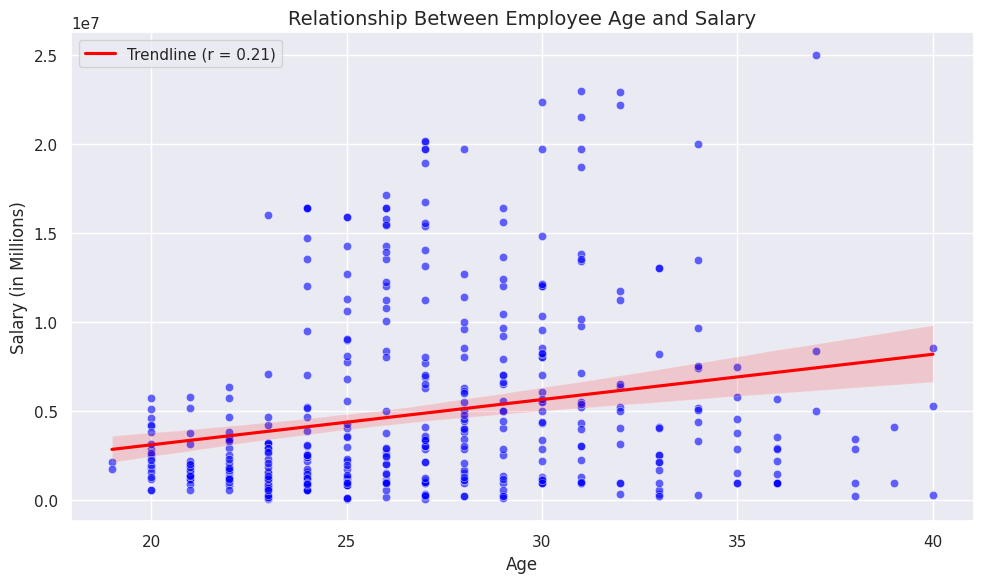

In [13]:
#5.
# Calculate the correlation coefficient
correlation = df['Age'].corr(df['Salary'])
print(f"Pearson correlation coefficient between Age and Salary: {correlation:.4f}\n")

# Visualize the relationship
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='Age', y='Salary', alpha=0.6, color='blue')
sns.regplot(data=df, x='Age', y='Salary', scatter=False, color='red', label=f'Trendline (r = {correlation:.2f})')

plt.title('Relationship Between Employee Age and Salary', fontsize=14)
plt.xlabel('Age', fontsize=12)
plt.ylabel('Salary (in Millions)', fontsize=12)
plt.legend()
plt.tight_layout()
plt.show()

**Graphical representation**

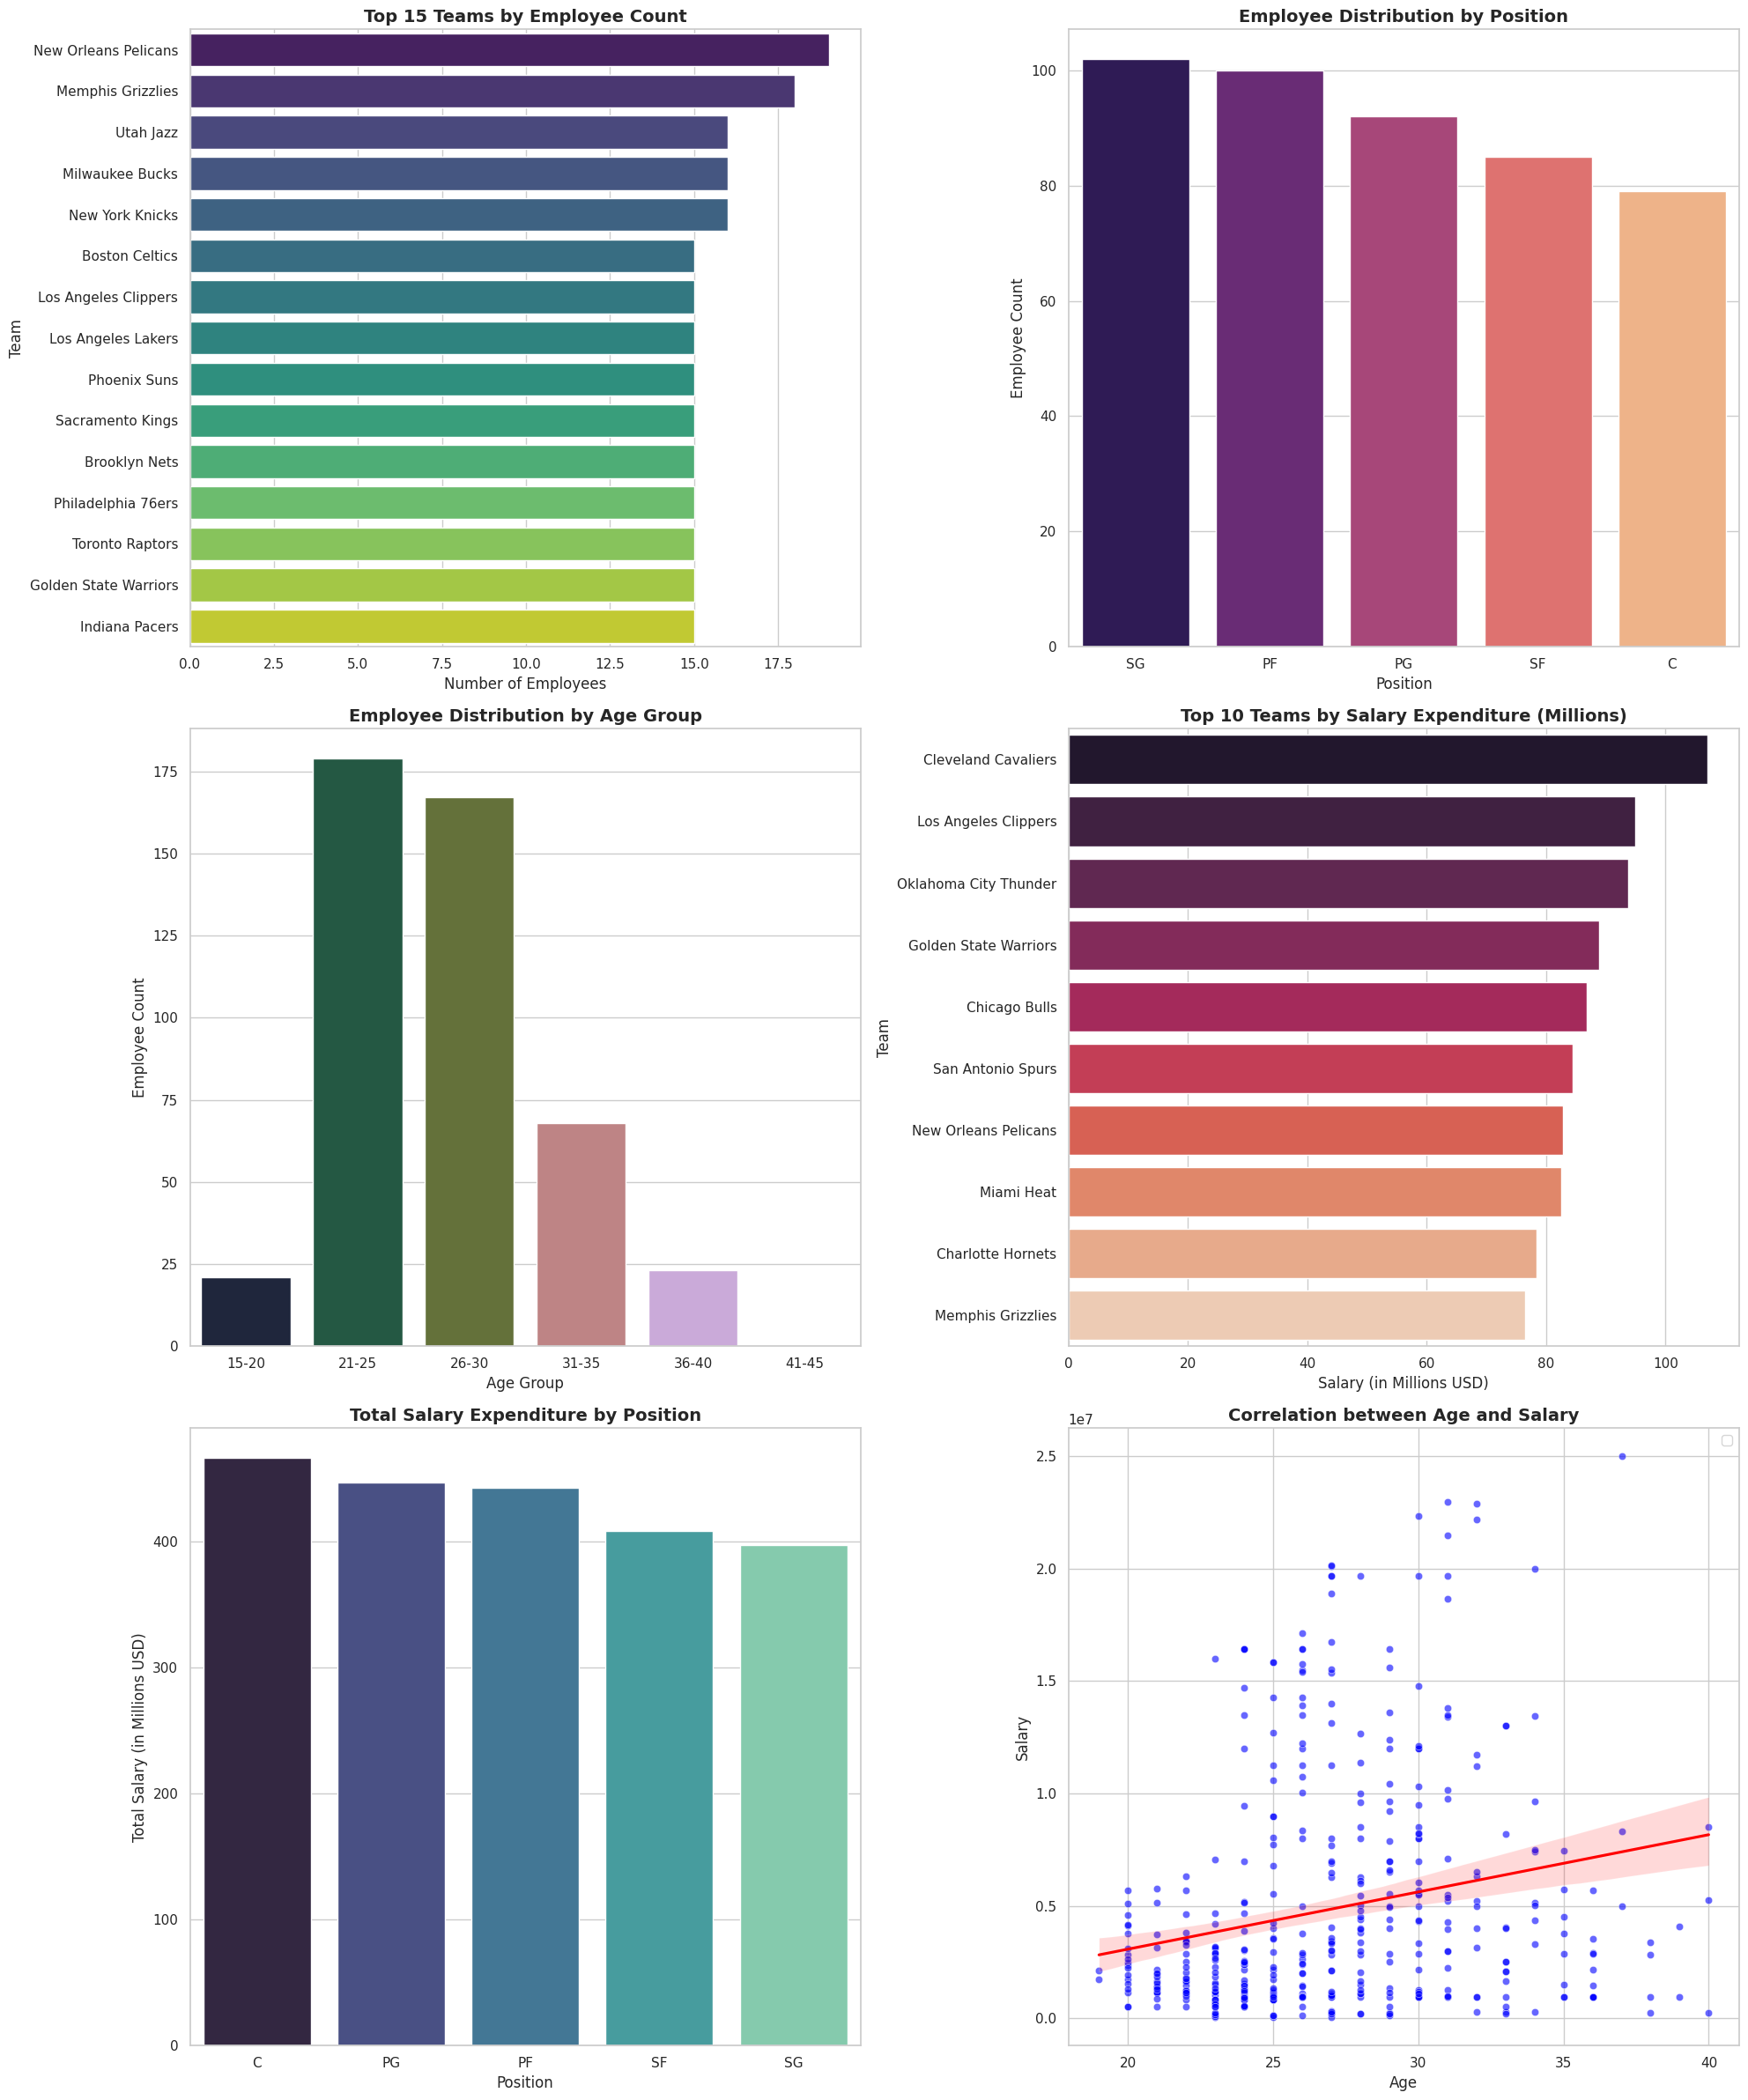

In [15]:


# Configure global style
sns.set_theme(style='whitegrid')
fig, axes = plt.subplots(3, 2, figsize=(20, 24))

# 1. Team Distribution (Top 15 Teams for readability)
sns.barplot(
    x=team_distribution['Employee Count'].head(15),
    y=team_distribution.head(15).index,
    ax=axes[0, 0],
    palette='viridis'
)
axes[0, 0].set_title('Top 15 Teams by Employee Count', fontsize=14, fontweight='bold')
axes[0, 0].set_xlabel('Number of Employees')
axes[0, 0].set_ylabel('Team')

# 2. Position Distribution
sns.barplot(
    x='Position',
    y='Employee Count',
    data=position_distribution,
    ax=axes[0, 1],
    palette='magma'
)
axes[0, 1].set_title('Employee Distribution by Position', fontsize=14, fontweight='bold')
axes[0, 1].set_xlabel('Position')
axes[0, 1].set_ylabel('Employee Count')

# 3. Age Group Distribution
sns.barplot(
    x=age_summary.index,
    y='Employee Count',
    data=age_summary,
    ax=axes[1, 0],
    palette='cubehelix'
)
axes[1, 0].set_title('Employee Distribution by Age Group', fontsize=14, fontweight='bold')
axes[1, 0].set_xlabel('Age Group')
axes[1, 0].set_ylabel('Employee Count')

# 4a. Salary Expenditure by Team (Top 10)
sns.barplot(
    x=team_salary.head(10).values / 1e6,
    y=team_salary.head(10).index,
    ax=axes[1, 1],
    palette='rocket'
)
axes[1, 1].set_title('Top 10 Teams by Salary Expenditure (Millions)', fontsize=14, fontweight='bold')
axes[1, 1].set_xlabel('Salary (in Millions USD)')
axes[1, 1].set_ylabel('Team')

# 4b. Salary Expenditure by Position
sns.barplot(
    x=position_salary.index,
    y=position_salary.values / 1e6,
    ax=axes[2, 0],
    palette='mako'
)
axes[2, 0].set_title('Total Salary Expenditure by Position', fontsize=14, fontweight='bold')
axes[2, 0].set_xlabel('Position')
axes[2, 0].set_ylabel('Total Salary (in Millions USD)')

# 5. Age vs Salary Scatter Plot
sns.scatterplot(
    x='Age',
    y='Salary',
    data=df,
    ax=axes[2, 1],
    alpha=0.6,
    color='blue'
)
sns.regplot(
    x='Age',
    y='Salary',
    data=df,
    scatter=False,
    ax=axes[2, 1],
    color='red',
    line_kws={'label': f'Trendline (r = {correlation:.2f})'}
)
axes[2, 1].set_title('Correlation between Age and Salary', fontsize=14, fontweight='bold')
axes[2, 1].set_xlabel('Age')
axes[2, 1].set_ylabel('Salary')
axes[2, 1].legend()

plt.tight_layout()
plt.show()

## Executive Summary & Data Story: ABC Company Employee Insights

### 1. Team Composition & Distribution
* **Top Teams:** **New Orleans Pelicans** (19 employees) and **Memphis Grizzlies** (18 employees) are the largest departments, representing the highest concentration of human resources.
* **General Spread:** Most other teams maintain a balanced workforce of around 15 employees (approximately **3.28%** of the total workforce per team).

### 2. Position Breakdown
* **Distribution:** The workforce is relatively well-distributed across positions. **Shooting Guards (SG)** lead with 102 employees, closely followed by **Power Forwards (PF)** with 100.
* **Smallest Group:** **Centers (C)** represent the smallest position group with 79 employees.

### 3. Age Profiling (The Predominant Group)
* **Youthful Workforce:** The age of employees ranges from **19 to 40 years**.
* **The Peak:** The **21–25** age group is highly predominant, comprising **179 employees (39.08%)**. Combined with the **26–30** age bracket (36.46%), over **75%** of the company's workforce is 30 years old or younger, highlighting a very energetic and youthful talent pool.

### 4. Financial Expenditure Analysis
* **Top Team Spender:** The **Cleveland Cavaliers** lead the company in salary investments, with a total expenditure of **$106,988,689.00**.
* **Top Position Spender:** Although **Centers (C)** are the fewest in number, they command the highest overall salary expenditure at **$466,377,332.00**, indicating that Center roles carry a significantly higher average salary rate than any other position.

### 5. Age vs. Salary Correlation
* **Weak Positive Correlation:** We observed a Pearson correlation coefficient of **0.2140**.
* **Key Takeaway:** There is a slight positive trend indicating that salaries tend to increase with age (reflecting experience). However, the weak coefficient shows that age is not the primary driver of salary. High-value outliers (superstars) earn maximum salaries even in their mid-to-late 20s, showing that position value and performance likely play a far greater role than age alone.